<a href="https://colab.research.google.com/github/Aryan-yadav7/ML_Learning/blob/main/iris_logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Features:", iris.feature_names)
print("Classes:", iris.target_names)

Dataset shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']


In [3]:
df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = [iris.target_names[i] for i in y]

print(df.head())
print("\nMissing values:\n", df.isnull().sum())
print("\nClass distribution:\n", df["species"].value_counts())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Class distribution:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Model training completed.")

Model training completed.


In [7]:
y_pred = model.predict(X_test_scaled)

print("Actual labels:   ", y_test[:10])
print("Predicted labels:", y_pred[:10])

Actual labels:    [0 2 1 1 0 1 0 0 2 1]
Predicted labels: [0 2 1 1 0 1 0 0 2 1]


In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", round(accuracy * 100, 2), "%")

Test Accuracy: 93.33 %


In [9]:
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names,
    zero_division=0
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



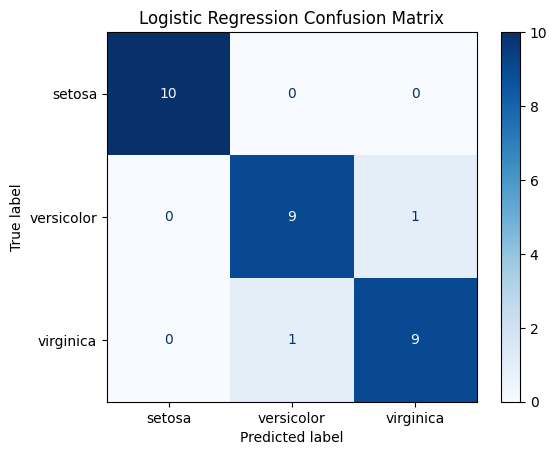

In [10]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [11]:
probabilities = model.predict_proba(X_test_scaled)

print("Probabilities for first test sample:")
for species, probability in zip(iris.target_names, probabilities[0]):
    print(f"{species}: {probability:.4f}")

print("\nPredicted species:", iris.target_names[y_pred[0]])
print("Actual species:", iris.target_names[y_test[0]])

Probabilities for first test sample:
setosa: 0.9788
versicolor: 0.0212
virginica: 0.0000

Predicted species: setosa
Actual species: setosa


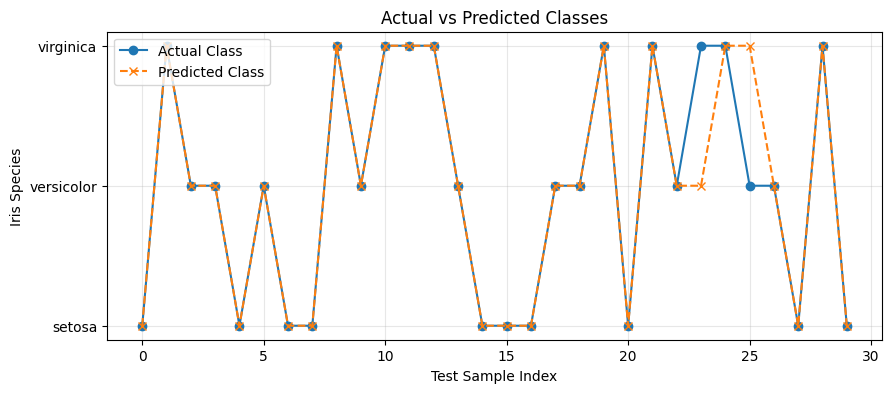

In [12]:
plt.figure(figsize=(10, 4))

plt.plot(y_test, "o-", label="Actual Class")
plt.plot(y_pred, "x--", label="Predicted Class")

plt.yticks(
    [0, 1, 2],
    iris.target_names
)

plt.xlabel("Test Sample Index")
plt.ylabel("Iris Species")
plt.title("Actual vs Predicted Classes")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
print("Model coefficients:")
print(model.coef_)

print("\nModel intercepts:")
print(model.intercept_)

Model coefficients:
[[-1.08894494  1.02420763 -1.79905609 -1.68622819]
 [ 0.53633654 -0.36048698 -0.20407418 -0.80795703]
 [ 0.5526084  -0.66372065  2.00313027  2.49418523]]

Model intercepts:
[-0.30558672  1.90855554 -1.60296882]
